## Project 2: Supervised Learning (Fraud Detection Pipeline)

### Goal: Build and tune a classification model to identify fraudulent transactions in a highly imbalanced dataset.

#### _Key Requirements:_

- Implement SMOTE (Synthetic Minority Over-sampling) to handle class imbalance.

- Train multiple algorithms (Logistic Regression, Random Forest) using Scikit-Learn.

- Discard "Accuracy" and evaluate the model using strict Precision, Recall, and ROC-AUC metrics.

##### _Key Skills: Classification algorithms, Scikit-Learn pipelines, imbalanced data handling, hyperparameter tuning._

In [ ]:
# Install & Import Required libraries
pip install imbalanced-learn scikit-learn pandas numpy

In [2]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE


In [27]:
# Load dataset
data = pd.read_csv('Dataset for Data Analytics - Sheet1.csv')
data.columns

Index(['OrderID', 'Date', 'CustomerID', 'Product', 'Quantity', 'UnitPrice',
       'ShippingAddress', 'PaymentMethod', 'OrderStatus', 'TrackingNumber',
       'ItemsInCart', 'CouponCode', 'ReferralSource', 'TotalPrice'],
      dtype='object')

In [4]:
data.head()

,OrderID,Date,CustomerID,Product,Quantity,UnitPrice,ShippingAddress,PaymentMethod,OrderStatus,TrackingNumber,ItemsInCart,CouponCode,ReferralSource,TotalPrice
0,ORD200000,2023-01-04,C72649,Monitor,5,570.62,928 Main St,Debit Card,Shipped,TRK37947903,7,SAVE10,Instagram,2853.10
1,ORD200001,2024-08-23,C75739,Phone,2,151.35,823 Main St,Online,Shipped,TRK91186779,3,SAVE10,Referral,302.70
2,ORD200002,2024-02-27,C81728,Tablet,5,550.68,512 Main St,Credit Card,Cancelled,TRK42903982,8,FREESHIP,Email,2753.40
3,ORD200003,2023-10-15,C33540,Chair,1,273.19,275 Main St,Debit Card,Returned,TRK62788070,5,SAVE10,Facebook,273.19
4,ORD200004,2025-05-08,C81840,Printer,4,626.01,668 Main St,Online,Delivered,TRK29241424,8,SAVE10,Email,2504.04


In [28]:
# Extract multiclass target variable - OrderStatus
y = data['OrderStatus']

In [29]:
# Drop non-predictive identifier columns to prevent ValueError
cols_to_drop = ['OrderStatus', 'OrderID', 'CustomerID', 'TrackingNumber', 'ShippingAddress']
X = data.drop(columns=cols_to_drop)

In [30]:
# Handle Date column to prevent further error

X['Date'] = pd.to_datetime(X['Date'])
X['Month'] = X['Date'].dt.month
X['DayOfWeek'] = X['Date'].dt.dayofweek
X = X.drop(columns=['Date'])

In [31]:
# Fill missing values & One-Hot Encode categorical feature columns

X['CouponCode'] = X['CouponCode'].fillna('None')
X = pd.get_dummies(X, columns=['Product', 'PaymentMethod', 'ReferralSource', 'CouponCode'], drop_first=True)

In [33]:
# Stratified train/test split - to prevent data leakage before scaling and Synthetic Minority Over-Sampling (SMOTE).

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [34]:
# Creating imblearn pipeline: Scaling -> SMOTE -> Multiclass Logistic Regression

lr_pipeline = ImbPipeline([
    ('scaler', StandardScaler()),
    ('smote', SMOTE(random_state=42)),
    ('classifier', LogisticRegression(
        multi_class='ovr', # Set to One-vs-Rest for multiclass
        solver='lbfgs', 
        max_iter=1000, 
        random_state=42))
])

lr_param_grid = {
    'classifier__C': [0.01, 0.1, 1.0, 10.0],
    'classifier__solver': ['lbfgs', 'liblinear']
}

In [35]:
# GridSearch with Cross-Validation

lr_grid = GridSearchCV(
    estimator=lr_pipeline,
    param_grid=lr_param_grid,
    scoring='f1_macro',
    cv=5,
    n_jobs=-1
)
# Model training
lr_grid.fit(X_train, y_train)

C:\Users\USER-PC\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1256: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. Use OneVsRestClassifier(LogisticRegression(..)) instead. Leave it to its default value to avoid this warning.
  warnings.warn(


GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('scaler', StandardScaler()),
                                       ('smote', SMOTE(random_state=42)),
                                       ('classifier',
                                        LogisticRegression(max_iter=1000,
                                                           multi_class='ovr',
                                                           random_state=42))]),
             n_jobs=-1,
             param_grid={'classifier__C': [0.01, 0.1, 1.0, 10.0],
                         'classifier__solver': ['lbfgs', 'liblinear']},
             scoring='f1_macro')

In [36]:
# Predicting on untouched test set

y_pred_lr = lr_grid.predict(X_test)
y_proba_lr = lr_grid.predict_proba(X_test)

# Evaluating Multiclass 

print("=== Multiclass Logistic Regression Results ===")
print("Best Params:", lr_grid.best_params_)
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred_lr))
print("\nClassification Reprort:\n", classification_report(y_test, y_pred_lr))

# Calculating Multiclass ROC-AUC using 'ovr' and 'macro' averaging
lr_auc = roc_auc_score(y_test, y_proba_lr, multi_class='ovr', average = 'macro')
print("Multiclass ROC-AUC (Macro):", lr_auc)

=== Multiclass Logistic Regression Results ===
Best Params: {'classifier__C': 0.1, 'classifier__solver': 'liblinear'}

Confusion Matrix:
 [[ 8 17  6  6 13]
 [ 6 16  8  8  8]
 [ 7  5 12 12 11]
 [ 6 13 14 10  7]
 [ 7 12 12 10  6]]

Classification Reprort:
               precision    recall  f1-score   support

   Cancelled       0.24      0.16      0.19        50
   Delivered       0.25      0.35      0.29        46
     Pending       0.23      0.26      0.24        47
    Returned       0.22      0.20      0.21        50
     Shipped       0.13      0.13      0.13        47

    accuracy                           0.22       240
   macro avg       0.21      0.22      0.21       240
weighted avg       0.21      0.22      0.21       240

Multiclass ROC-AUC (Macro): 0.5055977743189454


In [37]:
# Creating imblearn pipeline: SMOTE -> Random Forest (Trees are scale-invariant)

rf_pipeline = ImbPipeline([
    ('smote', SMOTE(random_state=42)),
    ('classifier', RandomForestClassifier(random_state=42, n_jobs=-1))
])

# Hyperparameter grid tuning for Random Forest
rf_param_grid = {
    'classifier__n_estimators': [100, 200],
    'classifier__max_depth': [10, 20, None]
}

rf_grid = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=rf_param_grid,
    scoring='f1_macro',
    cv=3, # 3-fold cross validation to speed up training
    n_jobs=-1
)


In [38]:
# Model training

rf_grid.fit(X_train, y_train)

# Predicting on untouched test set

y_pred_rf = rf_grid.predict(X_test)
y_proba_rf = rf_grid.predict_proba(X_test)

# Evaluating Multiclass

print("\n=== Multiclass Random Forest Results ===")
print("Best Params:", rf_grid.best_params_)
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred_rf))
print("\nClassification Report:\n", classification_report(y_test, y_pred_rf))

rf_auc = roc_auc_score(y_test, y_proba_rf, multi_class='ovr', average='macro')
print("Multiclass ROC-AUC (Macro):", rf_auc)


=== Multiclass Random Forest Results ===
Best Params: {'classifier__max_depth': 10, 'classifier__n_estimators': 100}

Confusion Matrix:
 [[ 6 13  8  9 14]
 [10  9 14  8  5]
 [ 9  5 15 10  8]
 [10  8 16  6 10]
 [ 8 15 15  6  3]]

Classification Report:
               precision    recall  f1-score   support

   Cancelled       0.14      0.12      0.13        50
   Delivered       0.18      0.20      0.19        46
     Pending       0.22      0.32      0.26        47
    Returned       0.15      0.12      0.13        50
     Shipped       0.07      0.06      0.07        47

    accuracy                           0.16       240
   macro avg       0.15      0.16      0.16       240
weighted avg       0.15      0.16      0.16       240

Multiclass ROC-AUC (Macro): 0.47576818948139377


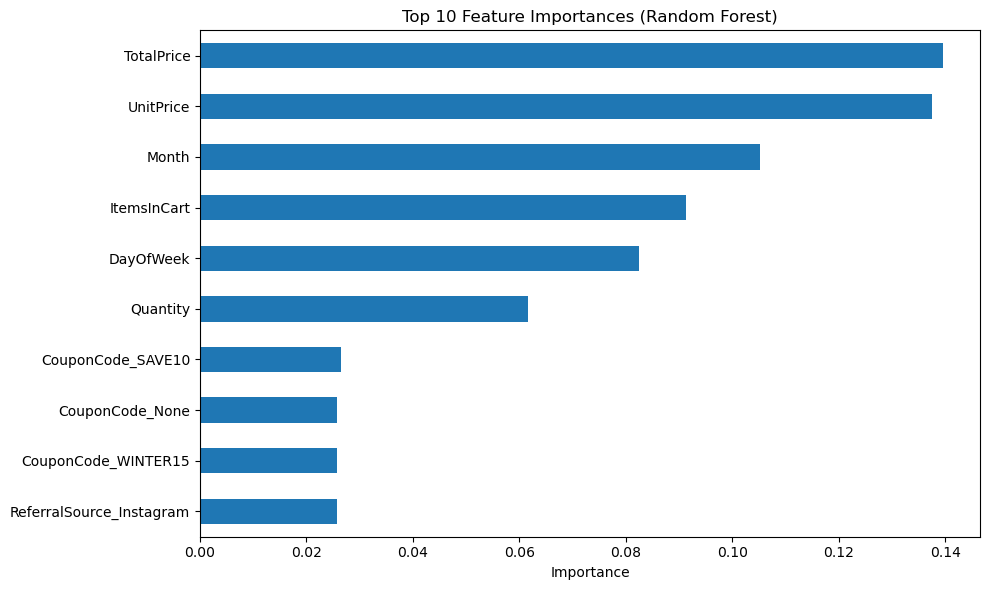

In [40]:
# Feature Importance Analysis - plotting feature importances to show which features drive fraud/status predictions.

import matplotlib.pyplot as plt
import pandas as pd

best_rf = rf_grid.best_estimator_.named_steps['classifier']
feature_importances = pd.Series(best_rf.feature_importances_, index=X.columns)

plt.figure(figsize=(10, 6))
feature_importances.nlargest(10).plot(kind='barh')
plt.title('Top 10 Feature Importances (Random Forest)')
plt.xlabel('Importance')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [41]:
# Summary Table - to compare model results

summary_data = pd.DataFrame({
    'Model': ['Logistic Regression', 'Random Forest'],
    'Best CV Score (F1 Macro)': [lr_grid.best_score_, rf_grid.best_score_],
    'Test ROC-AUC (Macro)': [lr_auc, rf_auc]
})

print(summary_data)

                 Model  Best CV Score (F1 Macro)  Test ROC-AUC (Macro)
0  Logistic Regression                  0.222866              0.505598
1        Random Forest                  0.182692              0.475768


In [42]:
# Saving predictions and final best model to a CSV file and exporting the trained model pipeline using joblib

import joblib

results_data = X_test.copy()
results_data['Actual_Status'] = y_test
results_data['LR_Prediction'] = y_pred_lr
results_data['RF_Prediction'] = y_pred_rf
results_data.to_csv('final_predictions.csv', index=False)

joblib.dump(rf_grid.best_estimator_, 'best_fraud_detection_pipeline.pkl')
print("Model and predictions saved successfully!")

Model and predictions saved successfully!
